# Binary word-frequency delta signal: grand average

Load the precomputed low-minus-high Zipf-frequency delta signals, average all runs (sessions) of each subject first, then average across subjects, and plot the result. Signals are stored under `RESULTS_DIR / 'binary_frequency' / subject / run_prefix / 'meg'` by `processing/run_binary_delta_activation.py`.

In [15]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import mne

project_root = next(
    (directory for directory in (Path.cwd(), *Path.cwd().parents)
     if (directory / 'config.py').is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError('Could not locate config.py from the current directory')
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

from config import RESULTS_DIR

In [16]:
def add_rms_axis(ax, times_ms, signal, band=0.2):
    """Draw the across-channel RMS on a right-hand axis, confined to the bottom `band` of the plot."""
    rms = np.sqrt(np.mean(signal**2, axis=0))
    low, high = ax.get_ylim()
    ax.set_ylim(low - (high - low) * band / (1 - band), high)  # reserve the bottom band for the RMS
    ax.set_yticks([tick for tick in ax.get_yticks() if low <= tick <= high])
    rms_ax = ax.twinx()
    rms_ax.fill_between(times_ms, rms, color='grey', alpha=0.2)
    rms_ax.plot(times_ms, rms, color='black', linewidth=1)
    rms_ax.set_ylim(0, rms.max() / band)
    rms_ax.set_yticks([tick for tick in rms_ax.get_yticks() if 0 <= tick <= rms.max()])
    rms_ax.set_ylabel('RMS across channels (fT/cm)')
    return rms_ax

In [17]:
signal_paths = sorted(
    (RESULTS_DIR / 'binary_whisper_base_by_low_frequency').glob('sub-*/*/meg/*_low-minus-high_binary_whisper_base_confidence.npz')
)
if not signal_paths:
    raise FileNotFoundError('No delta signals found. Run processing/run_binary_whisper_base_delta_activation.py first.')

signals_by_subject = {}
reference = None
for path in signal_paths:
    subject = path.name.split('_')[0]
    with np.load(path, allow_pickle=False) as result:
        signal = result['signal'] * 1e13
        channel_names = result['channel_names']
        times = result['times']
    if reference is None:
        reference = (channel_names, times)
    elif not (np.array_equal(channel_names, reference[0]) and np.array_equal(times, reference[1])):
        raise ValueError(f'Channels or times differ from the first run: {path}')
    signals_by_subject.setdefault(subject, []).append(signal)

channel_names, times = reference
# Average runs within each subject first, then average subjects (each subject weighs the same)
subject_signals = {subject: np.mean(runs, axis=0) for subject, runs in signals_by_subject.items()}
signal = np.mean(list(subject_signals.values()), axis=0)
run_prefix = signal_paths[0].name.removesuffix('_low-minus-high_binary_whisper_base_confidence.npz')

In [18]:
print(f'Subjects: {len(subject_signals)}, runs: {len(signal_paths)}')
for subject, runs in signals_by_subject.items():
    print(f'  {subject}: {len(runs)} runs')
print(f'Signal shape (channels, samples): {signal.shape}')
print(f'Time range: {times[0] * 1000:.1f} to {times[-1] * 1000:.1f} ms')

Subjects: 58, runs: 514
  sub-01: 9 runs
  sub-02: 9 runs
  sub-03: 9 runs
  sub-04: 9 runs
  sub-05: 9 runs
  sub-06: 9 runs
  sub-07: 9 runs
  sub-08: 9 runs
  sub-09: 8 runs
  sub-10: 9 runs
  sub-11: 9 runs
  sub-12: 9 runs
  sub-13: 9 runs
  sub-14: 9 runs
  sub-15: 9 runs
  sub-16: 9 runs
  sub-17: 8 runs
  sub-18: 9 runs
  sub-19: 9 runs
  sub-20: 9 runs
  sub-21: 8 runs
  sub-22: 9 runs
  sub-23: 5 runs
  sub-24: 9 runs
  sub-25: 9 runs
  sub-26: 9 runs
  sub-27: 9 runs
  sub-28: 9 runs
  sub-29: 9 runs
  sub-30: 9 runs
  sub-31: 9 runs
  sub-32: 9 runs
  sub-33: 9 runs
  sub-34: 9 runs
  sub-35: 9 runs
  sub-36: 9 runs
  sub-37: 9 runs
  sub-38: 9 runs
  sub-39: 9 runs
  sub-40: 9 runs
  sub-41: 9 runs
  sub-42: 9 runs
  sub-43: 9 runs
  sub-44: 9 runs
  sub-45: 9 runs
  sub-46: 9 runs
  sub-47: 9 runs
  sub-48: 9 runs
  sub-49: 9 runs
  sub-50: 9 runs
  sub-51: 9 runs
  sub-52: 9 runs
  sub-53: 9 runs
  sub-54: 9 runs
  sub-55: 9 runs
  sub-56: 8 runs
  sub-57: 9 runs
  sub-5

In [19]:
# We only need this for meg.info
from meg import Meg
meg = Meg(run_prefix, filter=True, maxwell=True)

/home/felipe/git/phd/meg/meg.py:238: RuntimeWarning: This file contains raw Internal Active Shielding data. It may be distorted. Elekta recommends it be run through MaxFilter to produce reliable results. Consider closing the file and running MaxFilter on the data.
  self.raw = mne.io.read_raw_fif(


Loaded bad-channel lists from /mnt/sda/data-output/phd/Pallier2025_results/preprocessing/sub-01/sub-01_ses-01_task-listen_run-01/meg/bad_channels.json.
Maxwell filtering started at 2026-10-21 09:28:18.
Maxwell filtering ended at 2026-10-21 09:28:27; elapsed 9.18 seconds.
Whisper large-v2: WER = 0.0335; NaNs in whisper_largev2_confidence = 1 / 1614
Whisper base: WER = 0.1152; NaNs in whisper_base_confidence = 9 / 1614
Filtering gradiometer data (0.5–20 Hz) started at 2026-10-21 09:28:27.
Filtering ended at 2026-10-21 09:28:30; elapsed 3.03 seconds.


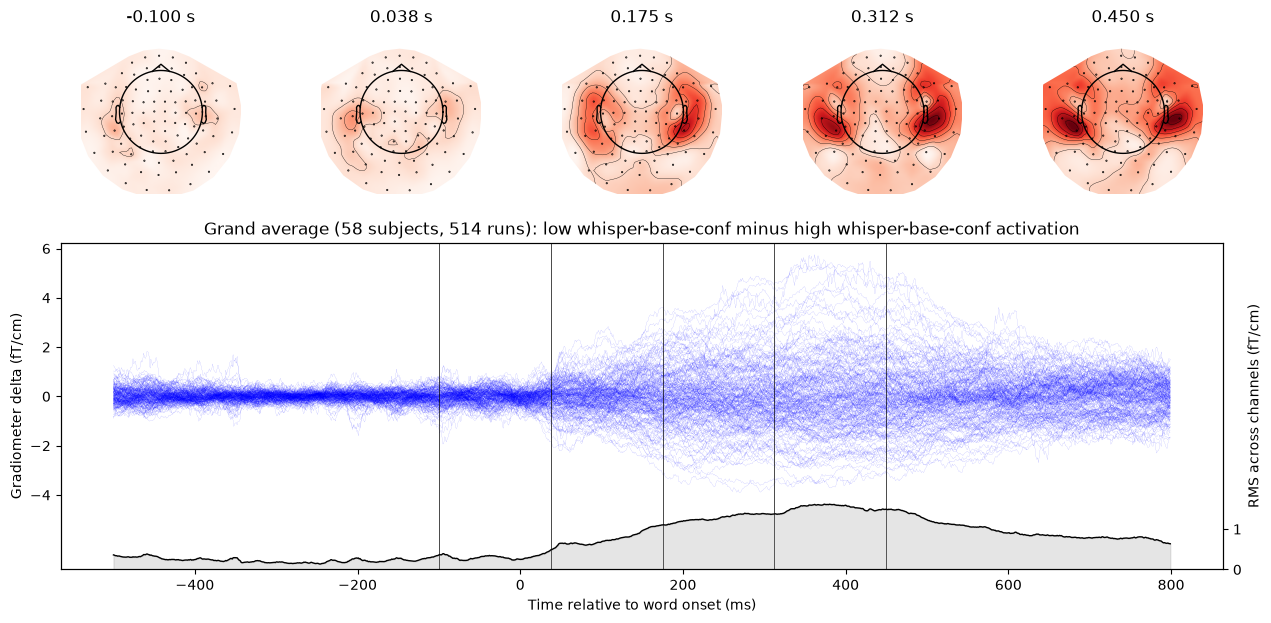

In [20]:
times_ms = times * 1000
before_ms = times_ms[0]

picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
info = mne.pick_info(meg.raw.info, picks)

# Assumes data has the same channel order as picks
evoked = mne.EvokedArray(signal, info, tmin=before_ms / 1000)

topo_times = [-0.100, 0.038, 0.175, 0.312, 0.450]
fig = plt.figure(figsize=(15, 7))
gs = fig.add_gridspec(2, 5, height_ratios=[1, 2])

topo_axes = [fig.add_subplot(gs[0, i]) for i in range(5)]
ax = fig.add_subplot(gs[1, :])

evoked.plot_topomap(
    times=topo_times,
    ch_type="grad",
    axes=topo_axes,
    cmap="Reds",
    colorbar=False,
    show=False,
)
ax.plot(times_ms, signal.T, color='blue', alpha=1, linewidth=0.05)
for t in topo_times:
    ax.axvline(t * 1000, color='k', linestyle='-', linewidth=0.5)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer delta (fT/cm)')
ax.set_title(f'Grand average ({len(subject_signals)} subjects, {len(signal_paths)} runs): low whisper-base-conf minus high whisper-base-conf activation')
# ax.set_ylim(-10, 10)
add_rms_axis(ax, times_ms, signal)
plt.show()

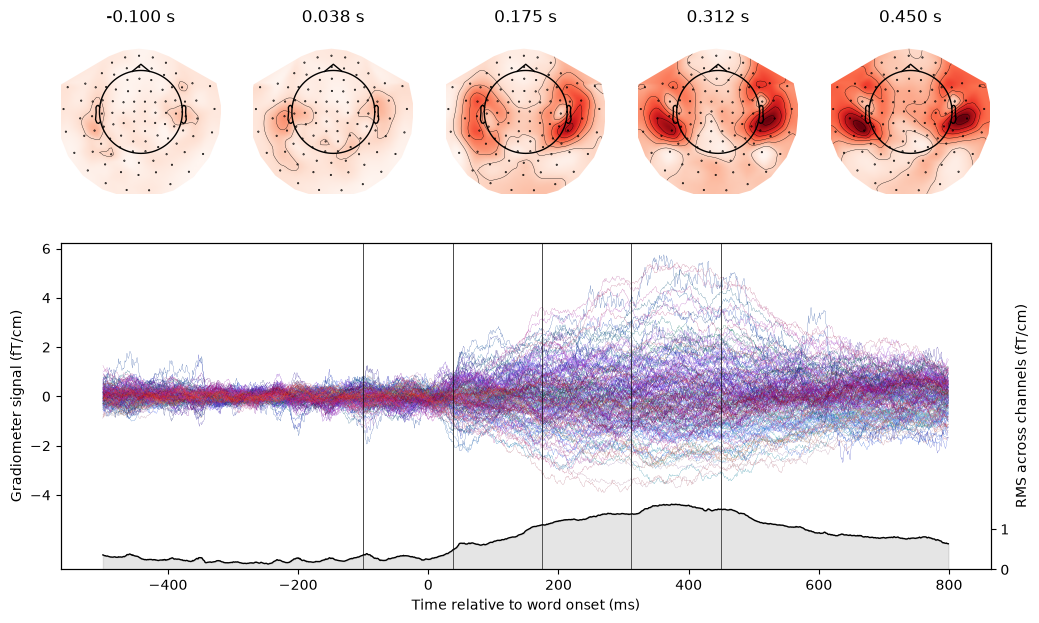

In [21]:
from mne.viz.evoked import _rgb
times_ms = times * 1000
before_ms = times_ms[0]

picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
info = mne.pick_info(meg.raw.info, picks)

# Assumes data has the same channel order as picks
evoked = mne.EvokedArray(signal, info, tmin=before_ms / 1000)

topo_times = [-0.100, 0.038, 0.175, 0.312, 0.450]
fig = plt.figure(figsize=(12, 7))
gs = fig.add_gridspec(2, 5, height_ratios=[1, 2])

topo_axes = [fig.add_subplot(gs[0, i]) for i in range(5)]
ax = fig.add_subplot(gs[1, :])

evoked.plot_topomap(
    times=topo_times,
    ch_type="grad",
    axes=topo_axes,
    cmap="Reds",
    colorbar=False,
    show=False,
)
ax.plot(times_ms, signal.T, color='blue', alpha=1, linewidth=0.05)
picks = mne.pick_types(meg.raw.info, meg="grad", exclude=[])
xyz = np.array([meg.raw.info["chs"][i]["loc"][:3] for i in picks])
colors = _rgb(*xyz.T)
assert len(colors) == signal.shape[0]
for sig, color in zip(signal, colors):
    ax.plot(times_ms, sig, color=color, alpha=1, linewidth=0.1)
for t in topo_times:
    ax.axvline(t * 1000, color='k', linestyle='-', linewidth=0.5)
ax.set_xlabel('Time relative to word onset (ms)')
ax.set_ylabel('Gradiometer signal (fT/cm)')
# ax.set_title(f'Grand average ({len(subject_signals)} subjects, {len(signal_paths)} runs): low-frequency minus high-frequency activation')
# ax.set_ylim(-10, 10)
add_rms_axis(ax, times_ms, signal)
plt.show()